## INF201 - Deliverable 1

### Group info:

ID: `G5_4`

Members:
* Stig Espen Paulsberg
* Vinicius Millan Santa Catharina
* Zaur Kambiev 

### Imports

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml

### Client ID

Read the client ID from `config.yaml`

In [5]:
with open("config.yaml") as file:
    config = yaml.safe_load(file)

client_id = config["met_api"]["client_id"]

### Task 1

Request data from Meteorologisk Institutt 

(example source https://frost.met.no/python_example.html)

In [30]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id, ''))

# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print(f'Error! Returned status code {r.status_code}')
    print(f'Message: {json['error']['message']}')
    print(f'Reason: {json['error']['reason']}')

Data retrieved from frost.met.no!


Convert JSON into DataFrame

In [ ]:
# This will return a Dataframe with all of the observations in a table format
table = pd.DataFrame()
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    table = pd.concat([table, row], ignore_index=True)

# These additional columns will be kept
columns = ['referenceTime', 'timeOffset', 'qualityCode', 'value', 'unit']
df = table[columns]

# Convert the time value to something Python understands
df['referenceTime'] = pd.to_datetime(df['referenceTime'])

df.head()

,referenceTime,timeOffset,qualityCode,value,unit
0,2025-01-01 00:00:00+00:00,PT0H,0.0,-5.2,degC
1,2025-01-01 00:00:00+00:00,PT6H,NaN,-2.8,degC
2,2025-01-02 00:00:00+00:00,PT0H,0.0,-11.5,degC
3,2025-01-02 00:00:00+00:00,PT6H,NaN,-7.2,degC
4,2025-01-03 00:00:00+00:00,PT0H,0.0,-8.9,degC


Check for missing values

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 728 entries, 0 to 727
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   referenceTime  728 non-null    datetime64[us, UTC]
 1   timeOffset     728 non-null    str                
 2   qualityCode    364 non-null    float64            
 3   value          728 non-null    float64            
 4   unit           728 non-null    str                
dtypes: datetime64[us, UTC](1), float64(2), str(2)
memory usage: 28.6 KB


Observations:
* We have two entries per day: `timeOffset = PT0H` and `timeOffset = PT6H`. 

* For `timeOffset = PT6H`, the `qualityCode` field is not filled. 

Decision: 
* We will use only entries with `timeOffset = PT0H`, as they have `qualityCode` of `0`, indicating the highest data quality.

In [70]:
df = df[df["timeOffset"] == "PT0H"]

Make a nicely formatted plot

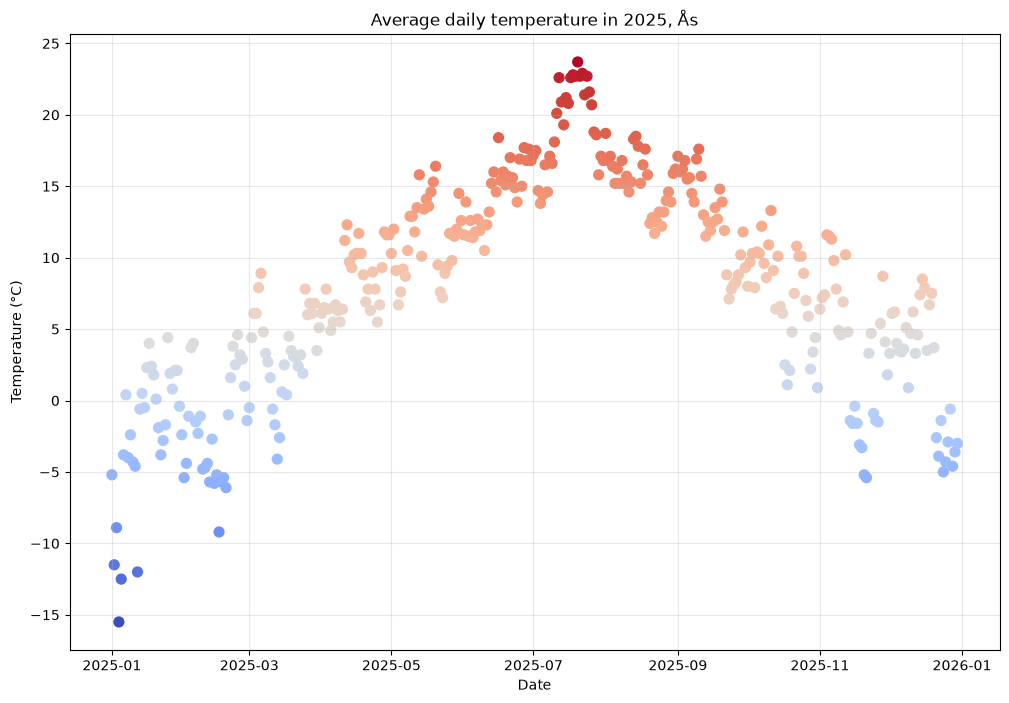

In [71]:
plt.figure(figsize=(12, 8))
temp_fig = plt.scatter(x=df['referenceTime'],
                       y=df['value'],
                       c=df['value'],
                       cmap='coolwarm',
                       s=50)

plt.grid(True, alpha=0.3)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.title('Average daily temperature in 2025, Ås')
plt.show()

Print a nicely formatted summary table

In [ ]:
stats = df["value"].agg(["mean", "median", "min", "max"])

print(
    f"{"Statistic":^20}{"Value":^20}\n"
    f"stats"
    f""
    f""
)


     Statistic             Value        


In [ ]:
from tabulate import tabulate

def summary_table(df):
    """
    Function to create a summary table of the temperature data.
    """
    # Calculate descriptive statistics
    summary = df["value"].agg(["mean", "median", "min", "max"])

    # Assign readable labels to the statistics
    summary.index = ["Mean", "Median", "Minimum", "Maximum"]

    # Display the summary as a formatted table
    print("Summary of Daily Air Temperature in Ås (2025)")

    print(tabulate(
        summary.reset_index(),
        headers=["Statistic", "Temperature (°C)"],
        tablefmt="outline",
        showindex=False,
        floatfmt=".2f"
    )
    )

### Task 2

### Task 3

### Task 4

### Task 5